## Simulador de paso de mensajes y algoritmos de consenso en redes estocasticas

Es `pruebas.ipynb` del proyecto original (`../Simulador/back/`), puesto al día: las
funciones ya no se definen aquí, se importan del motor que usa la aplicación
(`python/simulation/`). Así este notebook corre exactamente lo mismo que el
simulador. Las diferencias con el original están en `docs/MOTOR.md`.

In [24]:
import json
import sys

import matplotlib.pyplot as plt
import numpy as np

sys.dont_write_bytecode = True     # no dejar .pyc dentro de python/
sys.path.insert(0, "../python")

from simulation.algoritmos import ALGORITMOS, amp, fv, fv_batch, amp_batch
from simulation.barrido import round_batch
from simulation.ronda import get_adj, get_values, update_graph_data, who_gets_message

ex = "./k2.json"

### load_graph(file)
Esta función se encarga de cargar el archivo JSON del path

In [2]:
def load_graph(file):
    with open(file, "r") as j:
        return json.load(j)

def graph_info(data):
    nodes = data['nodes']
    edges = data['edges']
    directed = data['directed']

    print(f"Dirigida: {directed}")
    print(f"Nodos: {len(nodes)}")
    print(f"Aristas: {len(edges)}\n")

    print("=== Nodos ===")
    for node in nodes:
        print(f"  {node['id']} | valor: {node['value']}")

    print("\n=== Aristas ===")
    for edge in edges:
        arrow = "->" if directed else "<->"
        print(f"  {edge['id']} | {edge['source']} {arrow} {edge['target']} | p: {edge['weight']}")

def discrepancy(values):
    return max(values) - min(values)

In [3]:
data = load_graph(ex)
print(data)
matrix = get_adj(data)
print(matrix)
values = get_values(data)
print(values)

graph_info(data)
messages, probs = who_gets_message(matrix, data['directed'])
print(messages)
print(probs)

{'directed': True, 'nodes': [{'id': 'node_10', 'value': 1, 'position': {'x': 326.00974172697994, 'y': 368.45561481280527}}, {'id': 'node_11', 'value': 0, 'position': {'x': 495.6295911360882, 'y': 370.795198942586}}], 'edges': [{'id': 'edge_0', 'source': 'node_10', 'target': 'node_11', 'weight': '1'}, {'id': 'edge_1', 'source': 'node_11', 'target': 'node_10', 'weight': '1'}]}
[[0. 1.]
 [1. 0.]]
[1 0]
Dirigida: True
Nodos: 2
Aristas: 2

=== Nodos ===
  node_10 | valor: 1
  node_11 | valor: 0

=== Aristas ===
  edge_0 | node_10 -> node_11 | p: 1
  edge_1 | node_11 -> node_10 | p: 1
[[0 1]
 [1 0]]
[[0.         0.79458936]
 [0.18392433 0.        ]]


### Los algoritmos
`fv` y `amp` reciben `(matrix, values, messages, params)` y devuelven una lista de
`(valor_nuevo, emisor_elegido)`. A diferencia del original ya no devuelven la
discrepancia: se calcula aparte. `amp` toma `agreed` de `params`.

In [4]:
new_values = amp(matrix, values, messages, {"agreed": 0.5})
print("Valores: ", new_values)
print("Discrepancia: ", discrepancy([v[0] for v in new_values]))

Valores:  [(0.5, None), (0.5, None)]
Discrepancia:  0.0


In [5]:
new_values = fv(matrix, values, messages, {})
print("Valores: ", new_values)
print("Discrepancia: ", discrepancy([v[0] for v in new_values]))

Valores:  [(np.int64(0), 1), (np.int64(1), 0)]
Discrepancia:  1


### Codigo para una ronda
Una ronda se compone por:
- Calcular la matriz de mensajes
- Hacer el paso de mensajes con esa matriz y el algoritmo
- Devolver la matriz de valores actualizada

Cualquier algoritmo de `ALGORITMOS` sirve: se pasa su función `ronda`.

In [6]:
def round(algoritmo, matrix, values, times=1, params=None):
    new_values = []
    aux = values.copy()
    for i in range(times):
        messages, probs = who_gets_message(matrix, data['directed'])
        result = algoritmo(matrix, aux, messages, params or {})
        aux = np.array([v[0] for v in result])   # <- solo los valores, descarta el emisor
        new_values.append([aux, discrepancy(aux)])
    return new_values

new_values = round(ALGORITMOS["amp"]["ronda"], matrix, values)
print("Valores: ", new_values[-1][0])
print("Discrepancia: ", new_values[-1][1])

Valores:  [0.5 0.5]
Discrepancia:  0.0


### Version vectorizada (batch)
Igual que `round`, pero sobre `S` simulaciones a la vez (formas `(S, n)`).
`who_gets_message_batch`, `fv_batch`, `amp_batch` y `round_batch` viven en el motor.
Ojo: aquí `fired[s, source, target]` **no** está transpuesta.

### Gráficas de discrepancia
Calculamos la discrepancia de AMP y FV en un rango de probabilidades [0, 1] con saltos de 0.005, y vemos si son correctas

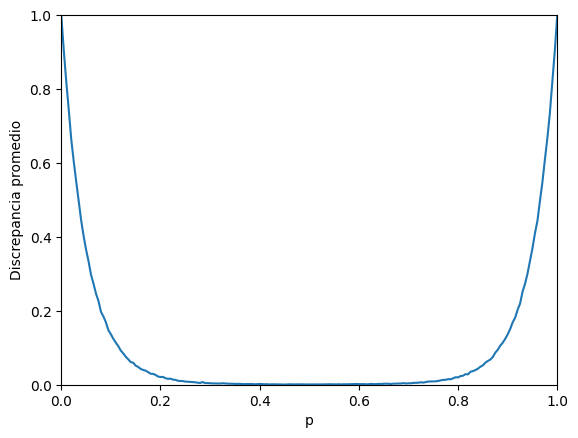

In [7]:
CANTSIM = 20000
TIMES = 10
AGREED = 0.5
ALGORITMO = "fv"        # <- cualquier clave de ALGORITMOS que tenga "batch": "fv" o "amp"

base_matrix = get_adj(data)
edge_mask = base_matrix > 0
directed = data['directed']

# linspace: 201 puntos uniformes en [0, 1] con AMBOS extremos exactos (incluye p = 1.0).
probabilities = np.linspace(0, 1, 201)
discrepanciasAverage = []

for p in probabilities:
    matrix = np.where(edge_mask, p, 0.0)
    # round_batch corre las CANTSIM simulaciones en paralelo (vectorizado) con el algoritmo dado
    vals = round_batch(ALGORITMOS[ALGORITMO]["batch"], matrix, values, directed, CANTSIM,
                       times=TIMES, params={"agreed": AGREED})
    disc = vals.max(axis=1) - vals.min(axis=1)           # discrepancia final por simulacion
    discrepanciasAverage.append(disc.mean())

plt.plot(probabilities, discrepanciasAverage)
plt.xlim(0, 1)
plt.ylim(0, np.max(values))
plt.xlabel("p")
plt.ylabel("Discrepancia promedio")
plt.show()

### update_json
Escribe el grafo con los valores nuevos en `<archivo>_updated.json`
(ignorado por git).

In [8]:
def update_json(file, data, new_values):
    new_file = file.replace('.json', '_updated.json')
    with open(new_file, "w") as j:
        json.dump(update_graph_data(data, new_values), j, indent=2)
    return new_file

In [9]:
new_values = fv(get_adj(data), values, who_gets_message(get_adj(data), data['directed'])[0], {})
update_json(ex, data, new_values)

'./k2_updated.json'

### Courteous y ciclo contra el paper
Simulaciones masivas de los dos protocolos de *Optimal One-Round Consensus with Five
Players*, en su modelo: 5 nodos, grafo completo, una ronda y broadcast (`por_emisor`).
Con valores 0 y 1, la discrepancia media es la probabilidad de desacuerdo, así que se
compara directamente con las fórmulas exactas del paper en **todos** los tipos de
entrada: 2 de courteous (Lema 2.1) y 6 de ciclo (Tabla 1).

Estas celdas solo dependen de la celda de imports.

In [ ]:
from simulation.barrido import run_one_simulation_naive

SIMS = 200_000     # por punto: error estándar de 0.0011 como máximo
PUNTOS = np.linspace(0, 1, 201)
BETA = 0.688042944721047
K5 = np.ones((5, 5)) - np.eye(5)

# Tipo de entrada -> (valores, error exacto como función de p). El último valor es L en ciclo.
ENTRADAS = {
    "courteous": {
        "1:4": ([0, 1, 1, 1, 1], lambda p, q: q**5 + 4*p**2*q**3),
        "2:3": ([0, 0, 1, 1, 1], lambda p, q: q**5 + 6*p**2*q**3 + 3*p**4*q),
    },
    "ciclo": {
        "k=0": ([1, 1, 1, 1, 0], lambda p, q: q**5 + 4*p*q**4 + 6*p**3*q**2),
        "k=1": ([0, 1, 1, 1, 0], lambda p, q: q - p**2*q**3),
        "k=2 adyacente": ([0, 0, 1, 1, 0], lambda p, q: q - p*q**4 - p**3*q**2),
        "k=2 opuesto": ([0, 1, 0, 1, 0], lambda p, q: q - p**3*q**2),
        "k=3": ([0, 0, 0, 1, 0], lambda p, q: q - 2*p*q**4),
        "k=4": ([0, 0, 0, 0, 0], lambda p, q: 0*p),
    },
}

def simular(algoritmo, valores, puntos=PUNTOS, sims=SIMS):
    batch = ALGORITMOS[algoritmo]["batch"]
    medias = []
    for p in puntos:
        vals = round_batch(batch, K5 * p, np.array(valores, float), True, sims, modo="por_emisor")
        medias.append((vals.max(axis=1) > vals.min(axis=1)).mean())
    return np.array(medias)

np.random.seed(2026)
simulado = {
    (alg, tipo): simular(alg, valores)
    for alg, tipos in ENTRADAS.items()
    for tipo, (valores, _) in tipos.items()
}
exacto = {
    (alg, tipo): formula(PUNTOS, 1 - PUNTOS)
    for alg, tipos in ENTRADAS.items()
    for tipo, (_, formula) in tipos.items()
}


In [ ]:
# ¿Las diferencias son del tamaño que produce el azar? Con el error estándar de cada punto,
# z debe comportarse como una normal: cerca de 5 % con |z| > 1.96 y z² promedio cerca de 1.
print(f"{'protocolo':10} {'entrada':14} {'máx |sim-exacto|':>17} {'máx |z|':>8} {'|z|>1.96':>9} {'z² medio':>9}")
todos = []
for clave, e in exacto.items():
    if clave == ("ciclo", "k=4"):
        assert simulado[clave].max() == 0, "con entrada unánime nunca debe haber desacuerdo"
        print(f"{clave[0]:10} {clave[1]:14} {0:17.5f} {'-':>8} {'-':>9} {'-':>9}")
        continue
    interior = (e > 0) & (e < 1)
    se = np.sqrt(e[interior] * (1 - e[interior]) / SIMS)
    z = (simulado[clave][interior] - e[interior]) / se
    todos.append(z)
    print(f"{clave[0]:10} {clave[1]:14} {np.abs(simulado[clave] - e).max():17.5f} "
          f"{np.abs(z).max():8.2f} {(np.abs(z) > 1.96).mean():9.1%} {(z**2).mean():9.2f}")
todos = np.concatenate(todos)
print(f"\nEn total: {todos.size} puntos, {(np.abs(todos) > 1.96).mean():.1%} con |z| > 1.96, "
      f"z² medio {(todos**2).mean():.3f}, máx |z| {np.abs(todos).max():.2f}")
assert 0.9 < (todos**2).mean() < 1.1, "las simulaciones no siguen a las fórmulas del paper"


protocolo  entrada         máx |sim-exacto|  máx |z|  |z|>1.96  z² medio
courteous  1:4                      0.00339     3.70      9.5%      1.29
courteous  2:3                      0.00340     3.16      6.0%      1.17
ciclo      k=0                      0.00274     3.01      8.0%      1.10
ciclo      k=1                      0.00324     3.60      2.0%      0.94
ciclo      k=2 adyacente            0.00232     2.98      1.5%      0.77
ciclo      k=2 opuesto              0.00345     3.15      6.0%      1.16
ciclo      k=3                      0.00361     3.30      5.0%      1.04
ciclo      k=4                      0.00000        -         -         -

En total: 1393 puntos, 5.5% con |z| > 1.96, z² medio 1.067, máx |z| 3.70


Peor caso exacto de courteous == C(p): True
Peor caso exacto de ciclo == A(p) desde p = 2/3: True
Máx |combinación simulada - U(p)|: 0.00340
Cruce simulado: p = 0.690 a 0.690; beta del paper = 0.688043


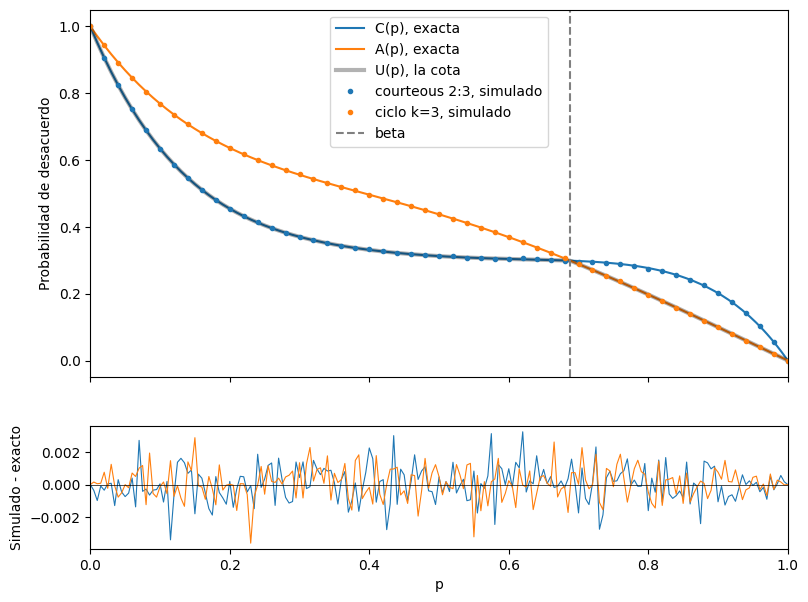

In [ ]:
# Peor caso de cada protocolo y la combinación de ambos: debe dar U(p) = min{C(p), A(p)}.
peor = {alg: np.max([simulado[c] for c in simulado if c[0] == alg], axis=0) for alg in ENTRADAS}
peor_exacto = {alg: np.max([exacto[c] for c in exacto if c[0] == alg], axis=0) for alg in ENTRADAS}
q = 1 - PUNTOS
C = q**5 + 6*PUNTOS**2*q**3 + 3*PUNTOS**4*q
A = q - 2*PUNTOS*q**4
U = np.minimum(C, A)
combinada = np.minimum(peor["courteous"], peor["ciclo"])

# Sin los extremos: ahí las dos curvas casi coinciden y el signo solo refleja el ruido.
zona = (PUNTOS >= 0.05) & (PUNTOS <= 0.95)
cambios = PUNTOS[zona][1:][np.diff(np.sign((peor["ciclo"] - peor["courteous"])[zona])) != 0]
print(f"Peor caso exacto de courteous == C(p): {np.allclose(peor_exacto['courteous'], C)}")
desde_dos_tercios = PUNTOS >= 2/3
print(f"Peor caso exacto de ciclo == A(p) desde p = 2/3: "
      f"{np.allclose(peor_exacto['ciclo'][desde_dos_tercios], A[desde_dos_tercios])}")
print(f"Máx |combinación simulada - U(p)|: {np.abs(combinada - U).max():.5f}")
print(f"Cruce simulado: p = {cambios.min():.3f} a {cambios.max():.3f}; beta del paper = {BETA:.6f}")

fig, (arriba, abajo) = plt.subplots(2, 1, figsize=(9, 7), sharex=True, height_ratios=[3, 1])
arriba.plot(PUNTOS, C, color="tab:blue", label="C(p), exacta")
arriba.plot(PUNTOS, A, color="tab:orange", label="A(p), exacta")
arriba.plot(PUNTOS, U, color="black", linewidth=3, alpha=0.3, label="U(p), la cota")
arriba.plot(PUNTOS[::4], simulado[("courteous", "2:3")][::4], ".", color="tab:blue", label="courteous 2:3, simulado")
arriba.plot(PUNTOS[::4], simulado[("ciclo", "k=3")][::4], ".", color="tab:orange", label="ciclo k=3, simulado")
arriba.axvline(BETA, color="gray", linestyle="--", label="beta")
arriba.set_ylabel("Probabilidad de desacuerdo")
arriba.legend()
abajo.plot(PUNTOS, simulado[("courteous", "2:3")] - C, color="tab:blue", linewidth=0.8)
abajo.plot(PUNTOS, simulado[("ciclo", "k=3")] - A, color="tab:orange", linewidth=0.8)
abajo.axhline(0, color="black", linewidth=0.5)
abajo.set_xlabel("p")
abajo.set_ylabel("Simulado - exacto")
plt.xlim(0, 1)
plt.show()


In [ ]:
# El otro camino del motor: `ronda` nodo por nodo, sin `batch`. Es más lento, por eso son menos.
SIMS_RONDA = 20_000
print(f"{'protocolo':10} {'entrada':8} {'p':>5} {'simulado':>9} {'exacto':>8} {'z':>6}")
for alg, tipo in (("courteous", "2:3"), ("ciclo", "k=3")):
    valores, formula = ENTRADAS[alg][tipo]
    for p in (0.25, 0.5, BETA, 0.8, 0.95):
        disc = [
            run_one_simulation_naive(K5 * p, np.array(valores, float), True, ALGORITMOS[alg]["ronda"],
                                     1, {}, "por_emisor")
            for _ in range(SIMS_RONDA)
        ]
        e = formula(p, 1 - p)
        z = (np.mean(disc) - e) / np.sqrt(e * (1 - e) / SIMS_RONDA)
        print(f"{alg:10} {tipo:8} {p:5.3f} {np.mean(disc):9.4f} {e:8.4f} {z:6.2f}")


protocolo  entrada      p  simulado   exacto      z
courteous  2:3      0.250    0.4058   0.4043   0.45
courteous  2:3      0.500    0.3186   0.3125   1.86
courteous  2:3      0.688    0.2983   0.2989  -0.19
courteous  2:3      0.800    0.2799   0.2768   1.00
courteous  2:3      0.950    0.1232   0.1229   0.15
ciclo      k=3      0.250    0.5890   0.5918  -0.79
ciclo      k=3      0.500    0.4381   0.4375   0.17
ciclo      k=3      0.688    0.3021   0.2989   1.00
ciclo      k=3      0.800    0.1981   0.1974   0.23
ciclo      k=3      0.950    0.0500   0.0500  -0.02


### Ciclo: ¿`ciclo_batch` equivale a `ciclo`?
Dos comprobaciones. La primera es sin azar: con los mismos mensajes, las dos versiones
deben decidir exactamente lo mismo. Cubre también entregas que un broadcast no produce,
donde un emisor llega solo a algunos nodos, porque el modo «Por arista» sí las genera.
La segunda corre las dos por el motor, cada una con su propio azar: como consumen
aleatoriedad en distinto orden, ahí solo se pueden comparar estadísticamente.

In [ ]:
from itertools import product

from simulation.algoritmos import ciclo, ciclo_batch
from simulation.barrido import run_one_simulation_naive

def primera_diferencia(vals, fired):
    """La primera simulación en que batch y ronda deciden distinto, o None."""
    salida = ciclo_batch(vals, fired, {})
    for s in range(len(vals)):
        ronda = [valor for valor, _ in ciclo(None, vals[s], fired[s].T.astype(int), {})]
        if not np.array_equal(salida[s], ronda):
            return vals[s], fired[s], salida[s], ronda
    return None

def exhaustivo(n):
    """Todas las entradas con todas las entregas posibles, arista por arista."""
    fuera_de_diagonal = [(i, j) for i in range(n) for j in range(n) if i != j]
    vals, fired = [], []
    for valores in product((0.0, 1.0), repeat=n):
        for bits in product((False, True), repeat=len(fuera_de_diagonal)):
            matriz = np.zeros((n, n), dtype=bool)
            for (i, j), bit in zip(fuera_de_diagonal, bits):
                matriz[i, j] = bit
            vals.append(valores)
            fired.append(matriz)
    return np.array(vals), np.array(fired)

def al_azar(n, casos):
    fired = np.random.rand(casos, n, n) < np.random.rand(casos, 1, 1)
    fired[:, np.arange(n), np.arange(n)] = False
    return np.random.randint(0, 2, (casos, n)).astype(float), fired

def por_emisor(n):
    """Todas las entradas con todos los conjuntos de emisores exitosos."""
    vals, fired = [], []
    for valores in product((0.0, 1.0), repeat=n):
        for exitos in product((False, True), repeat=n):
            matriz = np.tile(np.array(exitos)[:, None], (1, n))
            matriz[np.arange(n), np.arange(n)] = False
            vals.append(valores)
            fired.append(matriz)
    return np.array(vals), np.array(fired)

np.random.seed(2026)
casos = {
    "n=4, todas las entregas": exhaustivo(4),
    "n=5, broadcast completo": por_emisor(5),
    "n=6, broadcast completo": por_emisor(6),
    "n=7, broadcast completo": por_emisor(7),
    "n=5, entregas al azar": al_azar(5, 300_000),
    "n=6, entregas al azar": al_azar(6, 100_000),
    "n=8, entregas al azar": al_azar(8, 100_000),
}
for nombre, (vals, fired) in casos.items():
    diferencia = primera_diferencia(vals, fired)
    print(f"{nombre:26} {len(vals):>8} casos: {'idénticos' if diferencia is None else 'DIFIEREN'}")
    assert diferencia is None, diferencia


n=4, todas las entregas       65536 casos: idénticos
n=5, broadcast completo        1024 casos: idénticos
n=6, broadcast completo        4096 casos: idénticos


n=7, broadcast completo       16384 casos: idénticos


n=5, entregas al azar        300000 casos: idénticos


n=6, entregas al azar        100000 casos: idénticos


n=8, entregas al azar        100000 casos: idénticos


In [ ]:
# Por el motor: mismas condiciones, cada versión con su propio azar.
SIMS_COMPARA = 50_000
K5_compara = np.ones((5, 5)) - np.eye(5)
ENTRADAS_CICLO = {
    "k=0": [1, 1, 1, 1, 0], "k=1": [0, 1, 1, 1, 0], "k=2 ady": [0, 0, 1, 1, 0],
    "k=2 op": [0, 1, 0, 1, 0], "k=3": [0, 0, 0, 1, 0],
}
MODOS = {"broadcast": ("por_emisor", True), "por arista": ("por_arista", True), "por arista, no dirigido": ("por_arista", False)}

np.random.seed(2027)
zetas = {}
for nombre, (modo, dirigido) in MODOS.items():
    zetas[nombre] = []
    for valores in ENTRADAS_CICLO.values():
        v = np.array(valores, float)
        for p in (0.25, 0.5, 0.75, 0.9):
            m = K5_compara * p
            lote = round_batch(ciclo_batch, m, v, dirigido, SIMS_COMPARA, modo=modo)
            disc_lote = lote.max(axis=1) - lote.min(axis=1)
            disc_ronda = np.array([
                run_one_simulation_naive(m, v, dirigido, ciclo, 1, {}, modo)
                for _ in range(SIMS_COMPARA)
            ])
            se = np.sqrt((disc_lote.var() + disc_ronda.var()) / SIMS_COMPARA)
            zetas[nombre].append((disc_lote.mean() - disc_ronda.mean()) / se)

print(f"{'modo':26} {'comparaciones':>13} {'máx |z|':>8} {'|z|>1.96':>9} {'z² medio':>9}")
for nombre, z in zetas.items():
    z = np.array(z)
    print(f"{nombre:26} {z.size:13} {np.abs(z).max():8.2f} {(np.abs(z) > 1.96).mean():9.1%} {(z**2).mean():9.2f}")


modo                       comparaciones  máx |z|  |z|>1.96  z² medio
broadcast                             20     2.54      5.0%      0.77
por arista                            20     2.90     15.0%      1.64
por arista, no dirigido               20     2.24      5.0%      0.96


In [ ]:
from simulation.ronda import run_round

ALGORITMO = "fv"        # <- fv, amp o courteous; ciclo pide un grafo de al menos 4 nodos
MODO = "por_arista"     # <- por_arista o por_emisor (broadcast)
ARCHIVO = "./k2.json"

with open(ARCHIVO) as archivo:
    grafo = json.load(archivo)

resultado = run_round(grafo, ALGORITMO, modo=MODO)

print("Antes:       ", resultado["valuesBefore"])
print("Después:     ", resultado["values"])
print("Discrepancia:", resultado["discrepancy"])


Antes:        [1.0, 0.0]
Después:      [0.0, 1.0]
Discrepancia: 1.0


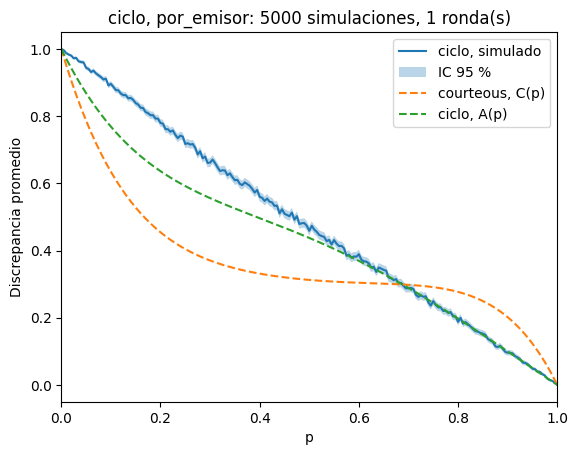

In [52]:
from simulation.barrido import iter_sweep

ALGORITMO = "ciclo"        # <- fv, amp o courteous; ciclo pide un grafo de al menos 4 nodos
MODO = "por_emisor"     # <- por_arista o por_emisor (broadcast)
ARCHIVO = "./k2.json"
SIMULACIONES = 5000     # <- por cada valor de p
RONDAS = 1
PUNTOS = 201            # <- valores de p entre 0 y 1
MOSTRAR_COTAS = True    # <- dibuja las cotas de courteous y ciclo (paper, 5 nodos)

with open(ARCHIVO) as archivo:
    grafo = json.load(archivo)

eventos = list(iter_sweep(grafo, ALGORITMO, num_p_points=PUNTOS, total_simulations_per_p=SIMULACIONES,
                          iterations=1, rounds=RONDAS, modo=MODO))
if eventos[-1]["type"] == "error":
    raise ValueError(eventos[-1]["message"])

puntos = eventos[-1]["points"]
p = [punto["p"] for punto in puntos]

plt.plot(p, [punto["mean"] for punto in puntos], label=f"{ALGORITMO}, simulado")
plt.fill_between(p, [punto["ciLow"] for punto in puntos], [punto["ciHigh"] for punto in puntos],
                 alpha=0.3, label="IC 95 %")

if MOSTRAR_COTAS:
    n = len(grafo["nodes"])
    if n == 5 and (get_adj(grafo) + np.eye(n) > 0).all() and MODO == "por_emisor" and RONDAS == 1:
        # A(p) es el peor caso de ciclo solo desde p = 2/3; antes es el error de la entrada k=3.
        p_cota = np.array(p)
        q_cota = 1 - p_cota
        plt.plot(p_cota, q_cota**5 + 6*p_cota**2*q_cota**3 + 3*p_cota**4*q_cota, "--", label="courteous, C(p)")
        plt.plot(p_cota, q_cota - 2*p_cota*q_cota**4, "--", label="ciclo, A(p)")
    else:
        print("Las cotas solo valen con 5 nodos, grafo completo, por_emisor y 1 ronda")

plt.xlim(0, 1)
plt.xlabel("p")
plt.ylabel("Discrepancia promedio")
plt.title(f"{ALGORITMO}, {MODO}: {SIMULACIONES} simulaciones, {RONDAS} ronda(s)")
plt.legend()
plt.show()
